In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../src")

In [3]:
DATA_DIR = "../data/troupe/TLS"

In [4]:
import pickle

with open(f"{DATA_DIR}/processed_data/trees.pkl", "rb") as f:
    data = pickle.load(f)

# print(type(data))
print('Number of trees: ', len(data))

Number of trees:  12


In [5]:
t_id = 11
t = data[t_id]
t.describe()
# t.convert_to_ultrametric()
# t.describe()

# t.show()
# t.write(outfile='test.nwk')

Number of leaf nodes:	138
Total number of nodes:	275
Rooted:	Yes
Most distant node:	AGATGCTGTGAGATCG-1
Max. distance:	0.993355


In [6]:
import networkx as nx

def ete_to_nx(t):
    G = nx.DiGraph()

    node_ids = {}
    
    for i, node in enumerate(t.traverse("preorder")):
        node_ids[node] = i + 1
    
    G.add_node(0, name="root", dist=0.0, is_leaf=False)

    for node in t.traverse("preorder"):
        node_id = node_ids[node]

        attrs = {
            "name": node.name,
            "dist": node.dist,
            "is_leaf": node.is_leaf()
        }

        for attr in ["state", "state_coarse", "state_fine"]:
            if hasattr(node, attr):
                attrs[attr] = getattr(node, attr)

        G.add_node(node_id, **attrs)

        if node.up:
            G.add_edge(node_ids[node.up], node_id, length=node.dist)
        else:
            G.add_edge(0, node_id, length=node.dist)

    G.graph["root"] = 0

    return G

In [7]:
T = ete_to_nx(t)
T

In [8]:
T.nodes(data=True)

NodeDataView({0: {'name': 'root', 'dist': 0.0, 'is_leaf': False}, 1: {'name': '', 'dist': 0.0066449770759561275, 'is_leaf': False}, 2: {'name': 'node_232', 'dist': 0.046374793170274466, 'is_leaf': False}, 3: {'name': 'node_238', 'dist': 0.006644976998620287, 'is_leaf': False}, 4: {'name': 'node_244', 'dist': 0.09508556807828979, 'is_leaf': False}, 5: {'name': 'node_250', 'dist': 0.0967763410451998, 'is_leaf': False}, 6: {'name': 'node_256', 'dist': 0.5932419640265092, 'is_leaf': False}, 7: {'name': 'CATAAGCAGGCACTAG-1', 'dist': 0.14858640166270679, 'is_leaf': True, 'state': 'Somite', 'state_coarse': 'Somite', 'state_fine': 'SomiteSclero'}, 8: {'name': 'CGCATAAGTAATCAGA-1', 'dist': 0.14858640166270679, 'is_leaf': True, 'state': 'Somite', 'state_coarse': 'Somite', 'state_fine': 'SomiteSclero'}, 9: {'name': 'node_251', 'dist': 0.44533857256503545, 'is_leaf': False}, 10: {'name': 'AACCTTTGTGATGAAT-1', 'dist': 0.29648979312418045, 'is_leaf': True, 'state': 'NeuralTube', 'state_coarse': 'Neu

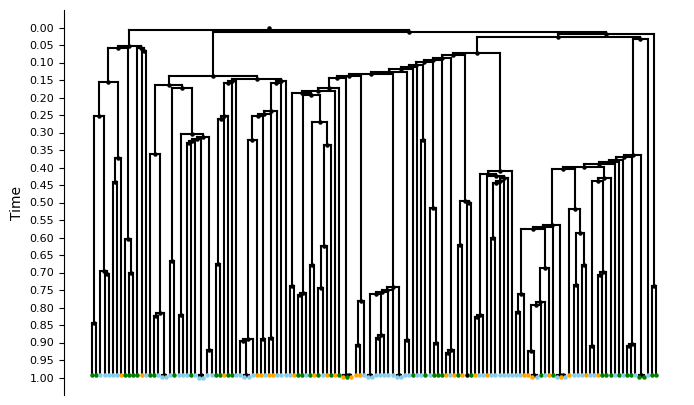

In [9]:
from plotters import draw_ultrametric_tree

draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False)

In [10]:
leaves = [n for n, d in T.out_degree() if d == 0]

In [11]:
# If edges have weight attribute 'length' or similar
distances = {}
for leaf in leaves:
    distances[leaf] = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='length')

In [12]:
min_dist = min(distances.values())
max_dist = max(distances.values())
print(min_dist, max_dist)

0.9933550209600294 0.9999999999999999


In [13]:
EPS = 1e-4
scale = (1 - EPS) / min_dist  # scale to make the min leaf at 1

In [14]:
for u, v, d in T.edges(data=True):
    d['length'] *= scale

In [15]:
for leaf in leaves:
    dist = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='length')
    
    if dist > 1.0:
        parent = list(T.predecessors(leaf))[0]
        
        edge_length = T[parent][leaf]['length']
        
        excess = dist - 1.0
        T[parent][leaf]['length'] = max(edge_length - excess, 0)  # avoid negative lengths

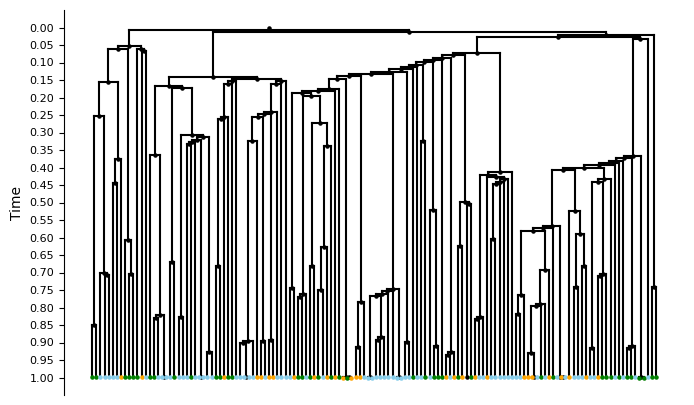

In [16]:
draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False)

In [17]:
import networkx as nx

def enforce_min_edge_length(G, root, min_length):
    """
    Adjust node times so that every edge satisfies

        T[parent] - T[child] >= min_length

    Leaves are kept fixed.
    Internal nodes are moved upward only when necessary.

    Updates:
        node['T']
        edge['length']

    Parameters
    ----------
    G : nx.DiGraph
        Rooted tree with parent -> child edges.
    root : node
        Root node.
    min_length : float
        Minimum allowed edge length.

    Returns
    -------
    nx.DiGraph
        Modified copy of G.
    """

    H = G.copy()

    # Postorder = children before parent
    for u in nx.dfs_postorder_nodes(H, root):

        children = list(H.successors(u))

        # leaf: fixed
        if not children:
            continue

        required_time = max(
            H.nodes[v]["T"] + min_length
            for v in children
        )

        # move parent upward only if necessary
        if H.nodes[u]["T"] < required_time:
            H.nodes[u]["T"] = required_time

    # recompute edge lengths
    for u, v in H.edges():
        H.edges[u, v]["length"] = (
            H.nodes[u]["T"] - H.nodes[v]["T"]
        )

    return H

In [18]:
from likelihood import add_node_times

T = add_node_times(T, root=T.graph['root'])

In [19]:
T = enforce_min_edge_length(T, root=T.graph['root'], min_length=0.01)

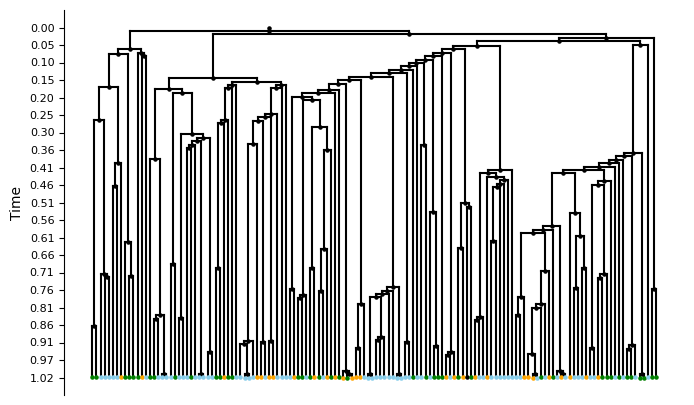

In [20]:
draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False)

In [21]:
# If edges have weight attribute 'length' or similar
distances = {}
for leaf in leaves:
    distances[leaf] = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='length')

In [22]:
min_dist = min(distances.values())
max_dist = max(distances.values())
print(min_dist, max_dist)

1.0164562018034675 1.0165562018034677


In [23]:
EPS = 1e-4
scale = (1 - EPS) / max_dist  # scale to make the min leaf at 1

In [24]:
scale

0.9836150703975658

In [25]:
for u, v, d in T.edges(data=True):
    d['length'] *= scale

In [26]:
scale

0.9836150703975658

In [27]:
from likelihood import add_node_times

T = add_node_times(T, root=T.graph['root'])

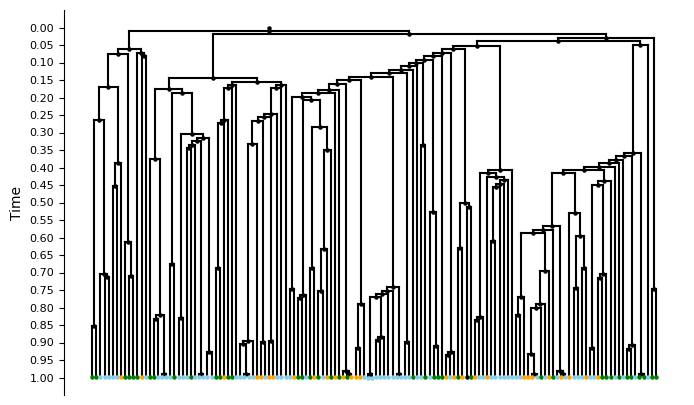

In [28]:
draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False)

In [29]:
from collections import defaultdict

cell_state_counts = defaultdict(int)

for node, d in T.nodes(data=True):
    if 'state' in d:
        cell_state_counts[d.get('state')] += 1

cell_state_counts

defaultdict(int, {'Somite': 40, 'NeuralTube': 69, 'NMPs': 28, 'PCGLC': 1})

In [30]:
T.nodes(data=True)

NodeDataView({0: {'name': 'root', 'dist': 0.0, 'is_leaf': False, 'T': 1}, 1: {'name': '', 'dist': 0.0066449770759561275, 'is_leaf': False, 'T': 0.9901638492960243}, 2: {'name': 'node_232', 'dist': 0.046374793170274466, 'is_leaf': False, 'T': 0.9372031077664625}, 3: {'name': 'node_238', 'dist': 0.006644976998620287, 'is_leaf': False, 'T': 0.924641250253859}, 4: {'name': 'node_244', 'dist': 0.09508556807828979, 'is_leaf': False, 'T': 0.8304974215057395}, 5: {'name': 'node_250', 'dist': 0.0967763410451998, 'is_leaf': False, 'T': 0.7346795654171339}, 6: {'name': 'node_256', 'dist': 0.5932419640265092, 'is_leaf': False, 'T': 0.14731314382174576}, 7: {'name': 'CATAAGCAGGCACTAG-1', 'dist': 0.14858640166270679, 'is_leaf': True, 'state': 'Somite', 'state_coarse': 'Somite', 'state_fine': 'SomiteSclero', 'T': 0.00019836042038268165}, 8: {'name': 'CGCATAAGTAATCAGA-1', 'dist': 0.14858640166270679, 'is_leaf': True, 'state': 'Somite', 'state_coarse': 'Somite', 'state_fine': 'SomiteSclero', 'T': 0.000

In [31]:
leaf_edge_length = 0
total_edge_length = 0

for u, v in T.edges():
    if len(list(T.successors(v))) == 0:  # v is a leaf
        leaf_edge_length += T.edges[u, v]['length']
    total_edge_length += T.edges[u, v]['length']

print(leaf_edge_length / total_edge_length)

0.6626910737488335


In [32]:
state_dict = {
    'MP': 0,
    'NMSTD': 1,
    'NMSD': 2,
    'NMS': 3,
    'NS': 4,
    'PGCLC': 5,
    'PCGLC': 5,
    'Endothelial': 6,
    'Endoderm': 7,
    'NMPs': 8,
    'Somite': 9,
    'NeuralTube': 10
}

In [33]:
for node, d in T.nodes(data=True):
    if 'state' in d:
        d['state'] = state_dict[d['state']]

In [34]:
from collections import defaultdict

cell_state_counts = defaultdict(int)

for node, d in T.nodes(data=True):
    if 'state' in d:
        cell_state_counts[d.get('state')] += 1

cell_state_counts

defaultdict(int, {9: 40, 10: 69, 8: 28, 5: 1})

In [ ]:
from scipy.special import logsumexp
import networkx as nx
import numpy as np
from math import log, ceil, floor

def calculate_Us(
    birth_rates: np.ndarray,
    death_rates: np.ndarray,
    sampling_rate: float,
    transition_probabilities: np.ndarray,
    one_by_delta_t: int = 1000,
    transition_filter: np.ndarray = None,
):
    num_states = len(birth_rates)
    delta_t = 1.0 / one_by_delta_t

    ####################################################################
    # Extinction probabilities U
    ####################################################################

    U = np.zeros((one_by_delta_t + 1, num_states))
    U[0, :] = 1.0 - sampling_rate

    for t in range(1, one_by_delta_t + 1):

        for s in range(num_states):

            next_transition_sum = sum(
                    transition_probabilities[s, d]
                    * delta_t
                    * U[t - 1, d]
                    for d in range(num_states)
                    if d != s
                    and (transition_filter is None or transition_filter[t, s, d])
            )

            U[t, s] = (
                (1.0
                 - (birth_rates[s]
                    + death_rates[s]
                    + transition_probabilities[s, :].sum())
                 * delta_t)
                * U[t - 1, s]
                + birth_rates[s]
                * delta_t
                * U[t - 1, s] ** 2
                + death_rates[s] * delta_t
                + next_transition_sum
            )
        
    return U


def calculate_LL_p(
    birth_rates: np.ndarray,
    death_rates: np.ndarray,
    sampling_rate: float,
    transition_probabilities: np.ndarray,
    U: np.ndarray,
    one_by_delta_t: int = 1000,
    transition_filter: np.ndarray = None,
):
    num_states = len(birth_rates)
    delta_t = 1.0 / one_by_delta_t

    LL_p = np.full((num_states, one_by_delta_t + 1, num_states), -np.inf)
    for sample_state in range(num_states):
        initial = np.full(num_states, -np.inf)
        initial[sample_state] = log(sampling_rate)
        LL_p[sample_state, 0, :] = initial
        previous = initial.copy()

        for t in range(1, one_by_delta_t + 1):

            current = np.full(num_states, -np.inf)

            A = (
                1.0
                - (birth_rates + death_rates + transition_probabilities.sum(axis=1)) * delta_t
                + 2.0
                * birth_rates
                * U[t - 1, :]
                * delta_t
            )

            for s in range(num_states):

                terms = []

                if A[s] > 0:
                    terms.append(
                        np.log(A[s]) + previous[s]
                    )

                for d in range(num_states):

                    if d == s:
                        continue

                    if transition_filter is not None and not transition_filter[t, s, d]:
                        continue

                    q = transition_probabilities[s, d]

                    if q > 0:
                        terms.append(
                            np.log(q * delta_t)
                            + previous[d]
                        )

                current[s] = logsumexp(terms)

            previous = current

            LL_p[sample_state, t, :] = current

    return LL_p






def calculate_log_likelihood_ctmc(
    T: nx.DiGraph,
    birth_rates: np.ndarray,
    death_rates: np.ndarray,
    transition_probabilities: np.ndarray,
    U: np.ndarray,
    LL_p: np.ndarray,
    one_by_delta_t: int = 1000,
    one_by_delta_t_approx: int = 50,
    transition_filter: np.ndarray = None,
):

    num_states = len(birth_rates)
    delta_t = 1.0 / one_by_delta_t

    total_rate = (
        birth_rates
        + death_rates
        + transition_probabilities.sum(axis=1)
    )

    ####################################################################
    # Postorder edge list
    ####################################################################

    postorder_edges = []


    for parent in nx.dfs_postorder_nodes(T):
        for child in T.successors(parent):
            postorder_edges.append((parent, child))

    edge_to_idx = {
        edge: idx
        for idx, edge in enumerate(postorder_edges)
    }
    num_edges = len(postorder_edges)

    # print(postorder_edges)

    ####################################################################
    # LL[e,s]
    # likelihood at parent end of edge
    ####################################################################

    def get_LL_at_time(previous, t, t_bin):
        delta_t = t - t_bin * (1.0 / one_by_delta_t)
        assert delta_t >= 0
        A = (
            1.0
            - (birth_rates + death_rates + transition_probabilities.sum(axis=1)) * delta_t
            + 2.0
            * birth_rates
            * U[t_bin, :]
            * delta_t
        )

        current = np.full(num_states, -np.inf)

        for s in range(num_states):

            terms = []

            if A[s] > 0:
                terms.append(
                    np.log(A[s]) + previous[s]
                )

            for d in range(num_states):

                if d == s:
                    continue

                if transition_filter is not None and not transition_filter[t_bin, s, d]:
                    continue

                q = transition_probabilities[s, d]

                if q > 0:
                    terms.append(
                        np.log(q * delta_t)
                        + previous[d]
                    )

            current[s] = logsumexp(terms)

        return current



    LL = np.full((num_edges, num_states), -np.inf)

    ####################################################################
    # Process edges bottom-up
    ####################################################################

    for edge_idx, (u, v) in enumerate(postorder_edges):

        parent_time = T.nodes[u]["T"]
        child_time = T.nodes[v]["T"]

        children = list(T.successors(v))

        e_t = int(floor(child_time * one_by_delta_t))
        s_t = int(floor(parent_time * one_by_delta_t))


        ###############################################################
        # likelihood at child event
        ###############################################################

        if len(children) == 0:

            child_state = T.nodes[v]["state"]
            
            LL[edge_idx] = get_LL_at_time(LL_p[child_state, s_t, :], parent_time, s_t)

            # print(f"Leaf edge {(u,v)}: child_state={child_state}, e_t={e_t}, s_t={s_t}, LL[edge_idx]={LL[edge_idx]}")

            continue


        elif len(children) == 2:

            c1, c2 = children

            LL1 = LL[edge_to_idx[(v,c1)]]
            LL2 = LL[edge_to_idx[(v,c2)]]

            if np.all(np.isneginf(LL1)):
                print("child edge not computed", (v,c1))

            if np.all(np.isneginf(LL2)):
                print("child edge not computed", (v,c2))

            initial = (
                np.log(birth_rates)
                + LL1
                + LL2
            )

        else:
            raise ValueError(
                f"Node {v} has {len(children)} children. "
                "Tree must be binary."
            )

        ###############################################################
        # discretized branch
        ###############################################################

        prev_U = np.zeros((num_states))
        dtu = child_time - (e_t) / one_by_delta_t
        assert dtu >= 0

        for s in range(num_states):

            next_transition_sum = sum(
                    transition_probabilities[s, d]
                    * dtu
                    * U[e_t, d]
                    for d in range(num_states)
                    if d != s
                    and (transition_filter is None or transition_filter[int(round(child_time * one_by_delta_t)), s, d])
            )

            prev_U[s] = (
                (1.0
                 - (birth_rates[s]
                    + death_rates[s]
                    + transition_probabilities[s, :].sum())
                 * dtu)
                * U[e_t, s]
                + birth_rates[s]
                * dtu
                * U[e_t, s] ** 2
                + death_rates[s] * dtu
                + next_transition_sum
            )


        previous = initial.copy()
        current = np.full(num_states, -np.inf)
        dt = (e_t + 1) / one_by_delta_t - child_time
        assert dt >= 0

        A = (
            1.0
            - total_rate * dt
            + 2.0
            * birth_rates
            * prev_U
            * dt
        )

        for s in range(num_states):

            terms = []

            if A[s] > 0:
                terms.append(
                    np.log(A[s]) + previous[s]
                )

            for d in range(num_states):

                if d == s:
                    continue

                if transition_filter is not None and not transition_filter[e_t + 1, s, d]:
                    continue

                q = transition_probabilities[s, d]

                if q > 0:
                    terms.append(
                        np.log(q * dt)
                        + previous[d]
                    )

            current[s] = logsumexp(terms)

        previous = current

        ###############################################################
        # propagate from child -> parent
        ###############################################################

        
        for t in range(e_t + 2, s_t):

            current = np.full(num_states, -np.inf)

            A = (
                1.0
                - total_rate * delta_t
                + 2.0
                * birth_rates
                * U[t - 1, :]
                * delta_t
            )

            for s in range(num_states):

                terms = []

                if A[s] > 0:
                    terms.append(
                        np.log(A[s]) + previous[s]
                    )

                for d in range(num_states):

                    if d == s:
                        continue

                    if transition_filter is not None and not transition_filter[t, s, d]:
                        continue

                    q = transition_probabilities[s, d]

                    if q > 0:
                        terms.append(
                            np.log(q * delta_t)
                            + previous[d]
                        )

                current[s] = logsumexp(terms)

            previous = current

        LL[edge_idx] = get_LL_at_time(previous, parent_time, s_t)

    ####################################################################
    # Root likelihood
    ####################################################################

    root = next(
        n for n in T.nodes
        if T.in_degree(n) == 0
    )

    root_children = list(T.successors(root))

    if len(root_children) != 1:
        raise ValueError(
            "Expected a dummy root with one child."
        )

    root_edge = edge_to_idx[(root, root_children[0])]

    print("LL at root edge:", root_edge, LL[root_edge])

    root_loglikelihood = LL[root_edge, 0]

    return root_loglikelihood, LL, U



transition_filter = np.full(
    (1001, 11, 11),
    True,
    dtype=bool
)


transition_probabilities = np.zeros((11, 11))

transition_probabilities[0, 1] = 1.0
transition_probabilities[0, 5] = 1.0
transition_probabilities[1, 2] = 1.0
transition_probabilities[1, 6] = 1.0
transition_probabilities[2, 3] = 1.0
transition_probabilities[2, 7] = 1.0
transition_probabilities[3, 4] = 1.0
transition_probabilities[3, 8] = 1.0
transition_probabilities[4, 9] = 1.0
transition_probabilities[4, 10] = 1.0


U = calculate_Us(
    birth_rates=np.array([5.0]*11),
    death_rates=np.array([.5]*11),
    sampling_rate=0.5,
    transition_probabilities=transition_probabilities,
    one_by_delta_t=1000,
    transition_filter=transition_filter
)

LL_p = calculate_LL_p(
    birth_rates=np.array([5.0]*11),
    death_rates=np.array([.5]*11),
    sampling_rate=0.5,
    transition_probabilities=transition_probabilities,
    U=U,
    one_by_delta_t=1000,
    transition_filter=transition_filter
)

calculate_log_likelihood_ctmc(
    T,
    birth_rates=np.array([5.0]*11),
    death_rates=np.array([.5]*11),
    transition_probabilities=transition_probabilities,
    U=U,
    LL_p=LL_p,
    one_by_delta_t=1000,
    transition_filter=None
)

LL at root edge: 274 [-433.85112987          -inf          -inf          -inf          -inf
          -inf          -inf          -inf          -inf          -inf
          -inf]


/var/folders/nz/jn74t1g51q10qyclfkkr8cgm0000gq/T/ipykernel_89746/317694171.py:204: RuntimeWarning: divide by zero encountered in log
  np.log(q * delta_t)


(np.float64(-433.85112987107055),
 array([[ -15.53318752,  -11.97405747,   -8.63988108, ...,          -inf,
           -0.8703732 ,          -inf],
        [ -15.53318752,  -11.97405747,   -8.63988108, ...,          -inf,
           -0.8703732 ,          -inf],
        [ -12.72679574,   -9.83902036,   -7.16759981, ...,          -inf,
                  -inf,   -1.20663448],
        ...,
        [ -43.14446961,  -39.07587753,  -35.43190296, ...,          -inf,
                  -inf,          -inf],
        [-392.25919718,          -inf,          -inf, ...,          -inf,
                  -inf,          -inf],
        [-433.85112987,          -inf,          -inf, ...,          -inf,
                  -inf,          -inf]], shape=(275, 11)),
 array([[0.5       , 0.5       , 0.5       , ..., 0.5       , 0.5       ,
         0.5       ],
        [0.499     , 0.499     , 0.499     , ..., 0.499     , 0.499     ,
         0.499     ],
        [0.49800051, 0.49800051, 0.49800051, ..., 0.498000

In [36]:
types = np.arange(11)

transition_maps = [
    (0, [1, 5]),
    (1, [2, 6]),
    (2, [3, 7]),
    (3, [4, 8]),
    (4, [9, 10])
]


# transition_maps = [
#     (0, [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]),
#     (1, [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]),
#     (2, [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]),
#     (3, [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]),
#     (4, [1, 2, 3, 4, 5, 6, 7, 8, 9, 10])
# ]

In [87]:
import numpy as np
from scipy.optimize import minimize
from scipy.special import expit as sigmoid

# MAX_DEATH = 1.0
MAX_BIRTH = 50.0
MAX_TRANSITION = 25.0
COUNT = 0


def unpack_params(theta):

    k = 0

    ####################################################
    # death rates
    ####################################################

    # death = np.zeros(len(types))

    # for i in range(len(types)):
    #     death[i] = MAX_DEATH * sigmoid(theta[k])
    #     k += 1

    death = np.array([0.0] * len(types))

    ####################################################
    # birth rates
    ####################################################

    birth = np.zeros(len(types))

    for i in range(len(types)):
        birth[i] = (
            death[i]
            + (MAX_BIRTH - death[i]) * sigmoid(theta[k])
        )
        k += 1

    ####################################################
    # transition rates
    ####################################################

    Q = np.zeros((len(types), len(types)))

    type_to_idx = {
        t: i
        for i, t in enumerate(types)
    }

    for src, transition_to in transition_maps:

        i = type_to_idx[src]

        for dst in transition_to:

            j = type_to_idx[dst]

            Q[i, j] = (
                MAX_TRANSITION
                * sigmoid(theta[k])
            )

            k += 1

    return birth, death, Q


def pack_initial():

    params = []

    # # death parameters
    # params.extend([0.0] * len(types))

    # birth parameters
    params.extend([0.0] * len(types))

    # transition parameters
    for _, transition_to in transition_maps:
        params.extend([0.0] * len(transition_to))

    return np.array(params)


def neg_log_likelihood(theta, trees, sampling_rate=0.5):

    birth, death, Q = unpack_params(theta)

    U = calculate_Us(
        birth_rates=birth,
        death_rates=death,
        sampling_rate=sampling_rate,
        transition_probabilities=Q,
        one_by_delta_t=1000,
        transition_filter=None
    )

    LL_p = calculate_LL_p(
        birth_rates=birth,
        death_rates=death,
        sampling_rate=sampling_rate,
        transition_probabilities=Q,
        U=U,
        one_by_delta_t=1000,
        transition_filter=None
    )

    total_nll = 0.0

    for tree in trees:

        ll, _, _ = calculate_log_likelihood_ctmc(
            T=tree,
            birth_rates=birth,
            death_rates=death,
            transition_probabilities=Q,
            U=U,
            LL_p=LL_p,
            one_by_delta_t=1000,
            one_by_delta_t_approx=50,
            transition_filter=None,
        )

        total_nll -= ll

    print(
        f"NLL={total_nll:.6f}",
        f"birth={birth}",
        f"death={death}",
    )

    write_iteration(birth, death, Q, total_nll)
    print("WROTE TO FILE")

    return total_nll



def find_params(trees, sampling_rate=0.5):

    theta0 = pack_initial()

    result = minimize(
        neg_log_likelihood,
        theta0,
        args=(trees, sampling_rate),
        method="L-BFGS-B",
        options={
            "disp": True,
            "maxiter": 500,
        },
    )

    birth, death, Q = unpack_params(result.x)


    print("\nOptimization finished")
    print("Success:", result.success)
    print("Message:", result.message)
    print("Log-likelihood:", -result.fun)
    print("Birth rates:", birth)
    print("Death rates:", death)
    print("Transition rates:")
    print(Q)


    return birth, death, Q, result

import pandas as pd
import os

CSV_DIR = "../outputs/tls/params"

def write_iteration(birth, death, Q, nll):

    global COUNT

    COUNT += 1

    os.makedirs(CSV_DIR + f"/{COUNT}", exist_ok=True)

    with open(f"{CSV_DIR}/{COUNT}/birth_rates.csv", "w") as f:
        for i, x in enumerate(birth):
            f.write(f"{i},{x}\n")

    with open(f"{CSV_DIR}/{COUNT}/death_rates.csv", "w") as f:
        for i, x in enumerate(death):
            f.write(f"{i},{x}\n")

    with open(f"{CSV_DIR}/{COUNT}/transition_rates.csv", "w") as f:
        for i in range(Q.shape[0]):
            for j in range(Q.shape[1]):
                if Q[i, j] > 0:
                    f.write(f"{i},{j},{Q[i, j]}\n")
    
    with open(f"{CSV_DIR}/{COUNT}/nll.txt", "w") as f:
        f.write(f"{nll}\n")
    
    print(f"Wrote iteration {COUNT} to {CSV_DIR}/{COUNT}/")

In [39]:
find_params([T])

/var/folders/nz/jn74t1g51q10qyclfkkr8cgm0000gq/T/ipykernel_61322/638094749.py:144: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  result = minimize(
/var/folders/nz/jn74t1g51q10qyclfkkr8cgm0000gq/T/ipykernel_61322/317694171.py:204: RuntimeWarning: divide by zero encountered in log
  np.log(q * delta_t)


LL at root edge: 274 [-1562.77841585           -inf           -inf           -inf
           -inf           -inf           -inf           -inf
           -inf           -inf           -inf]
NLL=1562.778416 birth=[25. 25. 25. 25. 25. 25. 25. 25. 25. 25. 25.] death=[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Wrote iteration 1 to ../outputs/tls/params/1/
WROTE TO FILE
LL at root edge: 274 [-1562.77841603           -inf           -inf           -inf
           -inf           -inf           -inf           -inf
           -inf           -inf           -inf]
NLL=1562.778416 birth=[25.00000012 25.         25.         25.         25.         25.
 25.         25.         25.         25.         25.        ] death=[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Wrote iteration 2 to ../outputs/tls/params/2/
WROTE TO FILE
LL at root edge: 274 [-1562.77841611           -inf           -inf           -inf
           -inf           -inf           -inf           -inf
           -inf           -inf           -inf]
NLL=1562.77

KeyboardInterrupt: 

In [51]:
ts = [t for t in data]

In [52]:
Ts = [ete_to_nx(t) for t in ts]

In [53]:
from dataprocessor import export_tree

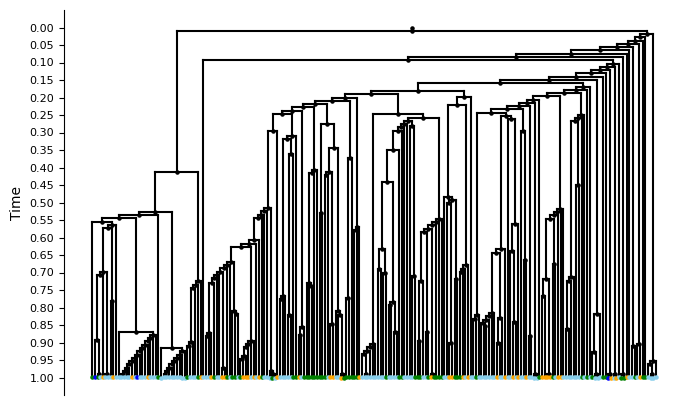

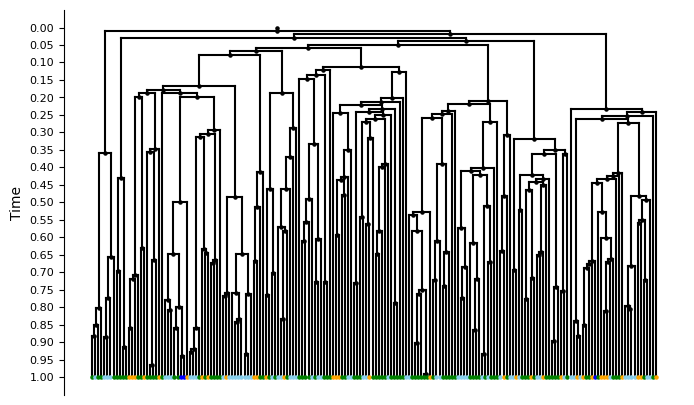

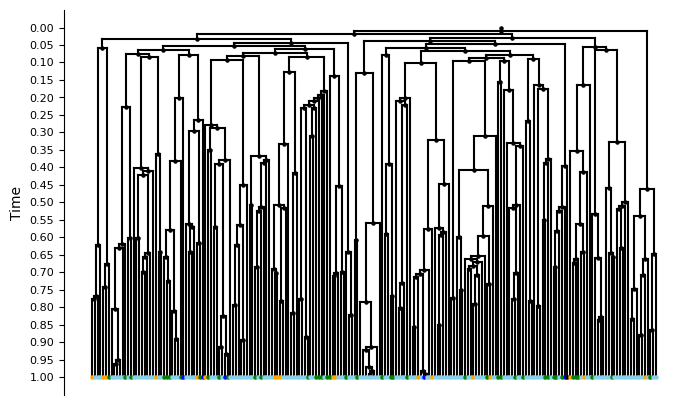

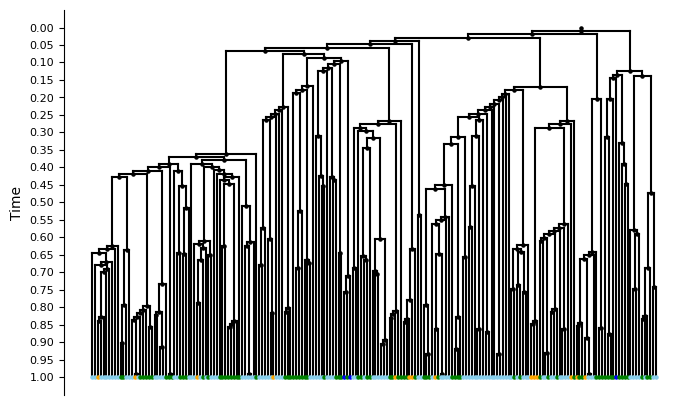

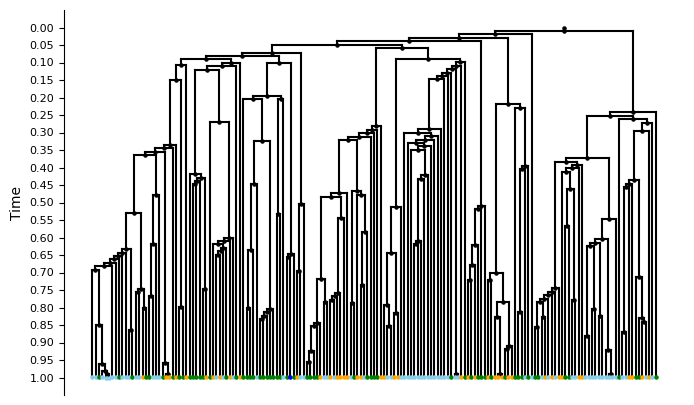

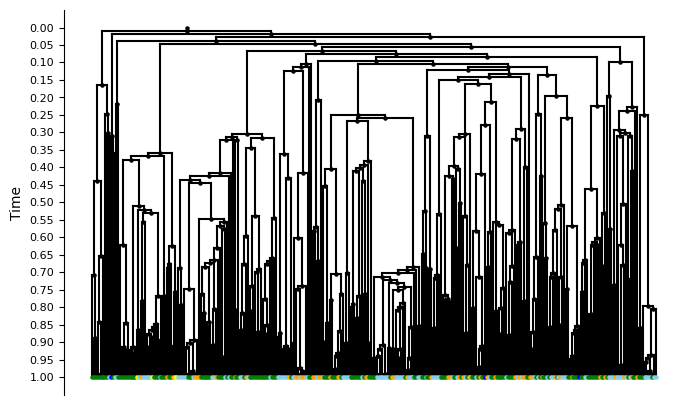

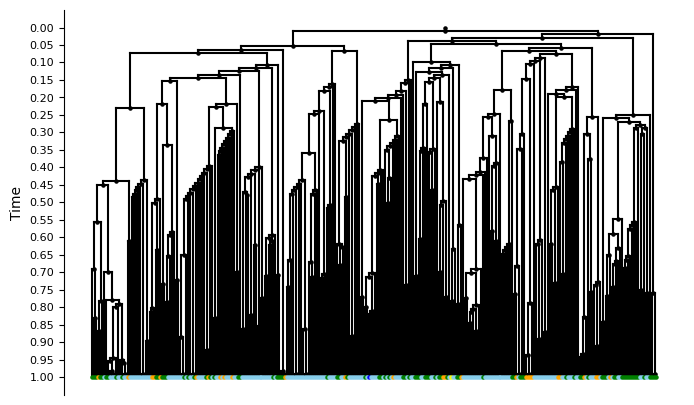

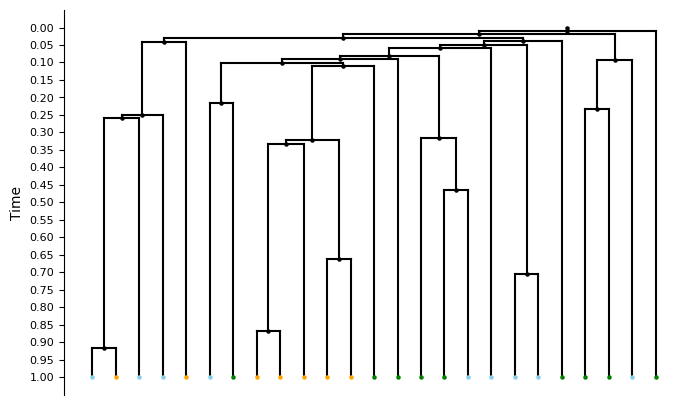

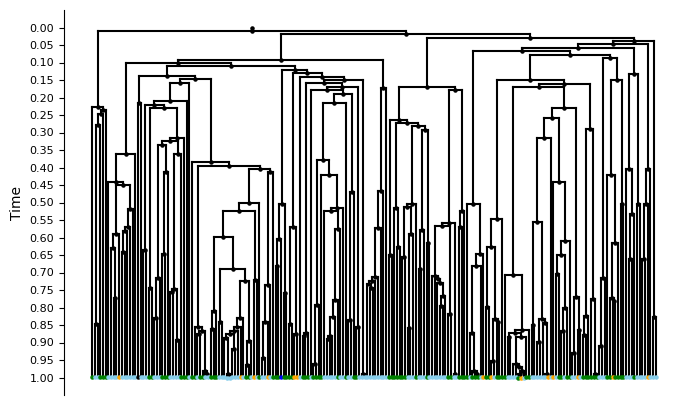

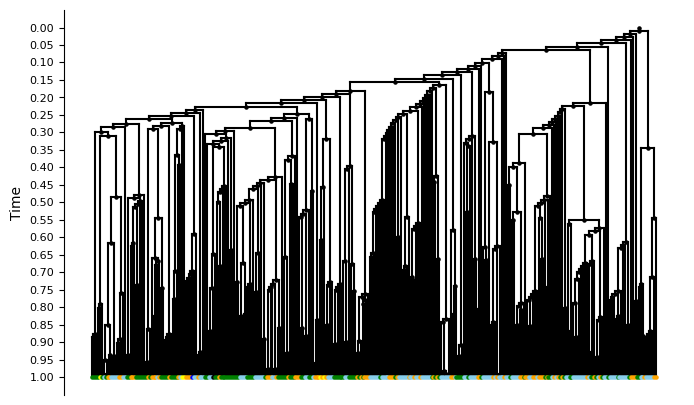

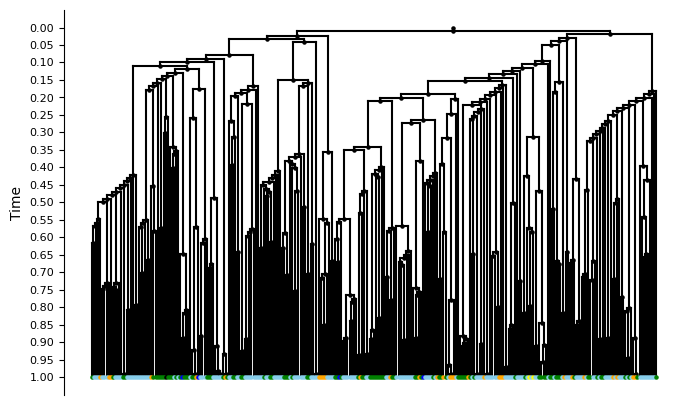

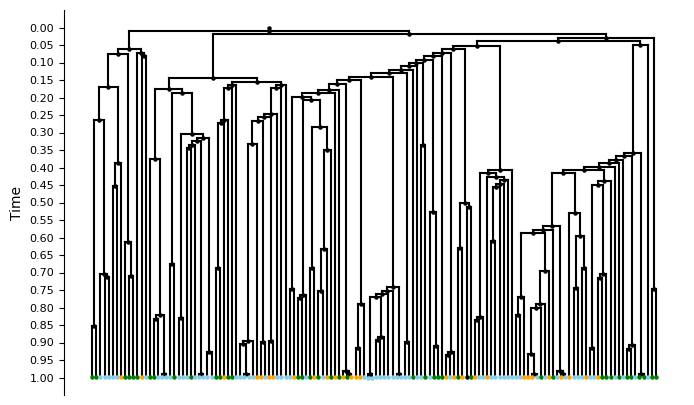

In [54]:
for i in range(len(Ts)):
    leaves = [n for n, d in Ts[i].out_degree() if d == 0]
    distances = {}
    for leaf in leaves:
        distances[leaf] = nx.shortest_path_length(Ts[i], source=Ts[i].graph['root'], target=leaf, weight='length')

    min_dist = min(distances.values())
    max_dist = max(distances.values())
    EPS = 1e-4
    scale = (1 - EPS) / min_dist  # scale to make the min leaf at 1

    for u, v, d in Ts[i].edges(data=True):
        d['length'] *= scale
    for leaf in leaves:
        dist = nx.shortest_path_length(Ts[i], source=Ts[i].graph['root'], target=leaf, weight='length')
        
        if dist > 1.0:
            parent = list(Ts[i].predecessors(leaf))[0]
            
            edge_length = Ts[i][parent][leaf]['length']
            
            excess = dist - 1.0
            Ts[i][parent][leaf]['length'] = max(edge_length - excess, 0)  # avoid negative lengths
    
    Ts[i] = add_node_times(Ts[i], root=Ts[i].graph['root'])
    Ts[i] = enforce_min_edge_length(Ts[i], root=Ts[i].graph['root'], min_length=0.01)

    # If edges have weight attribute 'length' or similar
    distances = {}
    for leaf in leaves:
        distances[leaf] = nx.shortest_path_length(Ts[i], source=Ts[i].graph['root'], target=leaf, weight='length')

    min_dist = min(distances.values())
    max_dist = max(distances.values())
    EPS = 1e-4
    scale = (1 - EPS) / max_dist  # scale to make the min leaf at 1

    for u, v, d in Ts[i].edges(data=True):
        d['length'] *= scale

    Ts[i] = add_node_times(Ts[i], root=Ts[i].graph['root'])
    draw_ultrametric_tree(Ts[i], root=Ts[i].graph['root'], add_labels=False)

    for node, d in Ts[i].nodes(data=True):
        if 'state' in d:
            d['state'] = state_dict[d['state']]
    
    export_tree(Ts[i], f"../data/troupe/TLS/processed_data/nodes_{i}.csv", f"../data/troupe/TLS/processed_data/edges_{i}.csv")
    


In [ ]:
global COUNT
COUNT = 0

find_params(Ts[:3])

/var/folders/nz/jn74t1g51q10qyclfkkr8cgm0000gq/T/ipykernel_61322/638094749.py:144: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  result = minimize(
/var/folders/nz/jn74t1g51q10qyclfkkr8cgm0000gq/T/ipykernel_61322/317694171.py:204: RuntimeWarning: divide by zero encountered in log
  np.log(q * delta_t)


LL at root edge: 426 [-1876.4551886 -1878.755991           -inf          -inf          -inf
          -inf          -inf          -inf          -inf          -inf
          -inf]
LL at root edge: 370 [-1985.95634296 -1992.93265386           -inf           -inf
           -inf           -inf           -inf           -inf
           -inf           -inf           -inf]
LL at root edge: 408 [-2322.97541485           -inf           -inf           -inf
           -inf           -inf           -inf           -inf
           -inf           -inf           -inf]
NLL=6185.386946 birth=[25. 25. 25. 25. 25. 25. 25. 25. 25. 25. 25.] death=[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Wrote iteration 1 to ../outputs/tls/params/1/
WROTE TO FILE
LL at root edge: 426 [-1876.45518873 -1878.755991             -inf           -inf
           -inf           -inf           -inf           -inf
           -inf           -inf           -inf]
LL at root edge: 370 [-1985.95634313 -1992.93265386           -inf           -inf
